## Проект “Моделирование жидкосцинтилляционного детектора”
### Общая концепция
Рассмотрим сферический детектор радиусом $R$, заполненный сцинтиллирующей жидкостью.
В сцинтилляторе свет от взаимодействия частиц излучается изотропно, выход фотонов для события с энергией 1 МэВ равен $Y$.
Внутренняя поверхность детектора покрыта $N$ фотоумножителями, улавливающими свет от взаимодействия частиц.
Считаем, что у фотоумножителя плоский фотокатод радиусом $r$.
Bероятность выбивания хотя бы одного фотоэлектрона равна $a$.
Каждому фотоумножителю соответствует канал набора данных, сохраняющий число фотоэлектронов.

### Задание 1
Создать класс Detector со следующими параметрами:

- $R$ = 2 метра
- $N$ = 40
- $r$ = 10 см
- $a$ = 0.5

Фотоумножители расположить по поверхности детектора достаточно равномерно. 
Координаты фотоумножителей сохранить в наиболее подходящую для этого структуру.
Разработать метод, определяющий, принадлежит ли точка на поверхности детектора какому-либо фотоумножителю. 
Визуализировать геометрию детектора с помощью пакета k3d (опционально).

In [95]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

class Detector:
    def __init__(self, radius: float = 2.0, pmt_number: int = 200, pmt_radius: float = 0.1, a: float = 0.5):
        self.radius = radius          # радиус сферического детектора, м
        self.pmt_number = pmt_number  # количество фотоумножителей на внутренней поверхности сферического детектора, штук
        self.pmt_radius = pmt_radius
        self.a = a                    # Bероятность выбивания хотя бы одного фотоэлектрона
        # фиксируем координату центра сферы
        self.center = np.array([0.0,0.0,0.0])
        self.pmt_centers, self.pmt_normals, self.pmt_phi_sph, self.pmt_theta_sph = self.place_pmts_on_sphere(pmt_number, radius)

    # функция равномерного распределения плоских круглых фотокатодов фотоумножителей радиуса r 
    # по внутренней поверхности сферы с радиусом R в Евклидовой системе отсчета (декартовы координаты)
    def place_pmts_on_sphere(self, N, R):                  # N - количество фотоумножителей, R - радиус сферического детектора
        # вводим индексы 0..N-1 сдвигаем на 0.5 → симметрия относительно полюсов    
        i = np.arange(N, dtype=float) + 0.5
        # z-координата: линейно от ≈+1 до ≈−1 (равномерно по площади единичной сферы, теорема Архимеда)
        z = 1.0 - 2.0 * i / N
        # радиус проекции точки на плоскость xy: ρ = √(1−z²); max(0,·) защищает от отрицательного под корнем
        rho = np.sqrt(np.maximum(0.0, 1.0 - z * z))
        # «золотой угол» ≈ 2.39996 рад — обеспечивает отсутствие спиральных артефактов
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        # азимутальный угол: каждый следующий фотоумножитель повёрнут на золотой угол
        phi = i * golden_angle
        # декартова x на единичной сфере: x = ρ·cos(φ)
        x = rho * np.cos(phi)
        # декартова y на единичной сфере: x = ρ·cos(φ)
        y = rho * np.sin(phi)
        # собираем (N,3)-массив и масштабируем на радиус R → координаты центров ФЭУ
        centers = R * np.column_stack([x, y, z])
        # нормаль внутрь сферы: минус единичный вектор центра
        normals = -centers / np.linalg.norm(centers, axis=1, keepdims=True)
        # полярный угол θ = arccos(z); clip защищает от |z|>1 из-за погрешностей округления
        theta = np.arccos(np.clip(z, -1.0, 1.0))
        # азимут φ в диапазоне [0, 2π): arctan2 даёт (−π,π] (по мсодулю)
        phi_sph = np.mod(np.arctan2(y, x), 2.0 * np.pi)
        #возвращается массив фотоумножителей с координатами, углами поворота, 
        #нормалями, азимутами относительно внутренней поверхности сферы
        return centers, normals, phi_sph, theta

    def check_overlaps(self, tol: float = 1e-9, raise_on_overlap: bool = False):
        """
        Проверяет, что плоские круглые фотокатоды радиуса self.pmt_radius
        не перекрываются на внутренней поверхности сферы радиуса self.radius.
        
        Два круга перекрываются, если геодезическое расстояние между их центрами
        по поверхности сферы меньше 2·r:
        d_geo(i, j) = R · arccos(u_i · u_j) < 2r,
        где u_i = C_i / |C_i| — единичные направления центров.
        
        Параметры:
        
        tol             : допуск (м) для численных сравнений;
                          перекрытием считается d_geo < 2r − tol
        raise_on_overlap: если True и найдены перекрытия — бросает ValueError
                          с диагностическим сообщением и рекомендацией по N

        Возвращает:

        overlaps : ndarray (M, 2) — пары индексов (i, j), i < j,
                   чьи фотокатоды пересекаются
        min_gap  : float — минимальный зазор между краями соседних кругов
                   по всем парам (отрицательный, если есть перекрытие)

        Пример:
            >>> det = Detector(radius=2.0, pmt_number=2000, pmt_radius=0.1)
            >>> overlaps, min_gap = det.check_overlaps()
            >>> len(overlaps)
            1284
            >>> min_gap < 0
            True
        """
        # 1) единичные направления центров ФЭУ: u_i = C_i / |C_i|
        u = self.pmt_centers / np.linalg.norm(self.pmt_centers, axis=1, keepdims=True)
        # 2) матрица косинусов углов между всеми парами: cos γ_ij = u_i · u_j
        #    clip защищает arccos от |cos| > 1 из-за погрешностей округления
        cos_gamma = np.clip(u @ u.T, -1.0, 1.0)
        # 3) геодезические расстояния по поверхности сферы: d_ij = R · γ_ij
        geo_dist = self.radius * np.arccos(cos_gamma)
        # 4) порог перекрытия: круги пересекаются, если d_ij < 2r − tol
        threshold = 2.0 * self.pmt_radius
        mask = geo_dist < threshold - tol
        # 5) убираем диагональ (сам с собой) и дубли (i,j)/(j,i)
        np.fill_diagonal(mask, False)
        mask = np.triu(mask, k=1)
        # 6) список перекрывающихся пар
        overlaps = np.argwhere(mask)                     # (M, 2), i < j
        # 7) минимальный зазор по всем парам (верхний треугольник, без диагонали)
        upper = geo_dist[np.triu_indices_from(geo_dist, k=1)]
        min_gap = float(upper.min() - threshold) if upper.size else float('inf')
        # 8) реакция на перекрытия
        if overlaps.size and raise_on_overlap:
            i, j = overlaps[0]
            raise ValueError(
                f"Обнаружено {len(overlaps)} перекрытий фотокатодов "
                f"(r = {self.pmt_radius} м, R = {self.radius} м).\n"
                f"Первая пара: ФЭУ #{i} и #{j}, "
                f"геодезическое расстояние = {geo_dist[i, j]:.4f} м, "
                f"требуется ≥ {threshold:.4f} м.\n"
                f"Минимальный зазор по всем парам: {min_gap:+.4f} м.\n"
                f"Рекомендация: уменьшить N до ≈ {self.pmt_number*0.95} "
                f"или уменьшить r."
           )
        return overlaps, min_gap

    # визуализация распределения центров фотокатодов по поверхности детектора
    def plot_pmt_centres(self):
        fig = plt.figure(figsize=(7, 7))
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(self.pmt_centers[:, 0], self.pmt_centers[:, 1], self.pmt_centers[:, 2],
            s=20, c=self.pmt_theta_sph, cmap='viridis')
        ax.set_box_aspect([1, 1, 1])
        ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
        ax.set_title(f'Равномерное распределение {det.pmt_number} ФЭУ по сфере R={det.radius} м')
        plt.tight_layout()
        plt.show()


# конвертация систем координат

def cartesian_to_spherical(points, degrees = False):
    """
    Преобразует декартовы координаты (x, y, z) в сферические (r, theta, phi).
    Параметры:
        points : array_like, shape (..., 3)
        degrees : bool — если True, углы возвращаются в градусах
    Возвращает:
        r     : ndarray, shape (...)   — расстояние от центра
        theta : ndarray, shape (...)   — полярный угол от оси +z, [0, π]
        phi   : ndarray, shape (...)   — азимутальный угол от +x, [0, 2π)
    """
    pts = np.asarray(points, dtype=float)
    x, y, z = pts[..., 0], pts[..., 1], pts[..., 2]
    r = np.sqrt(x*x + y*y + z*z)
    # защита от деления на ноль в центре
    with np.errstate(invalid = 'ignore', divide = 'ignore'):
        cos_theta = np.where(r > 0, z / r, 1.0)
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    theta = np.arccos(cos_theta)                  # [0, π]
    phi = np.mod(np.arctan2(y, x), 2.0 * np.pi)   # [0, 2π)
    if degrees:
        theta = np.degrees(theta)
        phi   = np.degrees(phi)
    return r, theta, phi

def spherical_to_cartesian(r, theta, phi, degrees=False):
    """Обратное преобразование (r, theta, phi) → (x, y, z)."""
    if degrees:
        theta = np.radians(theta)
        phi   = np.radians(phi)
    sin_t = np.sin(theta)
    x = r * sin_t * np.cos(phi)
    y = r * sin_t * np.sin(phi)
    z = r * np.cos(theta)
    return np.stack([x, y, z], axis=-1)

In [98]:
det = Detector(pmt_number = 950)

overlaps, min_gap = det.check_overlaps()
overlaps, min_gap

(array([], shape=(0, 2), dtype=int64), 0.0007118159071047014)

In [86]:
# тесты

# Проверка: все точки на сфере
det = Detector()
assert np.allclose(np.linalg.norm(det.pmt_centers, axis=1), det.radius)
# Проверка равномерности: распределение по косинусу полярного угла ~ равномерно
print(f"Равномерность распределения фотоумножителей по поверхности деткетора")
cos_theta = np.cos(det.pmt_theta_sph)
print(f"min/max cos(theta): {cos_theta.min():.3f} / {cos_theta.max():.3f}")
print(f"среднее: {cos_theta.mean():.3f}, ст. отклонение: {cos_theta.std():.3f}")
# Проверка упаковки: минимальное расстояние между соседними ФЭУ
# (грубая оценка: для площади 4πR²/N на один ФЭУ диаметр ≈ 2·sqrt(S/π))
print(f"Расстояние между соседними фотоумножителями")
S_per_pmt = 4.0 * np.pi * det.radius * det.radius / det.pmt_number
d_typical = 2.0 * np.sqrt(S_per_pmt / np.pi)
print(f"Средний шаг между ФЭУ ≈ {d_typical:.1f} м, диаметр фотокатода = {2*det.pmt_radius:.1f} м")

Равномерность распределения фотоумножителей по поверхности деткетора
min/max cos(theta): -0.995 / 0.995
среднее: 0.000, ст. отклонение: 0.577
Расстояние между соседними фотоумножителями
Средний шаг между ФЭУ ≈ 0.6 м, диаметр фотокатода = 0.2 м


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ============================================================
# Визуализация: отдельная функция
# ============================================================
def plot_detector(det, show_sphere=True, show_normals=False,
                  highlight_overlaps=True, figsize=(10, 10), dpi=100):
    """
    Рисует сферический детектор и фотокатоды ФЭУ как закрашенные круги,
    ориентированные по нормали к сфере.

    Параметры:
        det                : объект Detector с атрибутами
                             radius, pmt_number, pmt_radius, pmt_centers
        show_sphere        : рисовать каркасную сферу
        show_normals       : рисовать стрелки нормалей (к центру)
        highlight_overlaps : подкрашивать красным круги, участвующие в перекрытиях
        figsize, dpi       : параметры фигуры matplotlib

    Возвращает:
        fig, ax : объекты matplotlib
    """
    # --- 1) достаём параметры из объекта ---
    R = det.radius
    N = det.pmt_number
    r = det.pmt_radius
    centers = det.pmt_centers

    # --- 2) ищем перекрытия (для подсветки и статуса в заголовке) ---
    if highlight_overlaps:
        overlaps, min_gap = find_overlaps(centers, R, r)
        overlap_idx = set(overlaps.flatten().tolist()) if overlaps.size else set()
    else:
        overlaps, min_gap = np.empty((0, 2), dtype=int), float('nan')
        overlap_idx = set()

    # --- 3) фигура и 3D-оси ---
    fig = plt.figure(figsize=figsize, dpi=dpi)
    ax = fig.add_subplot(111, projection='3d')

    # --- 4) каркасная сфера ---
    if show_sphere:
        uu = np.linspace(0, 2 * np.pi, 48)
        vv = np.linspace(0, np.pi, 24)
        xs = R * np.outer(np.cos(uu), np.sin(vv))
        ys = R * np.outer(np.sin(uu), np.sin(vv))
        zs = R * np.outer(np.ones_like(uu), np.cos(vv))
        ax.plot_wireframe(xs, ys, zs, color='lightgray', linewidth=0.4, alpha=0.5)

    # --- 5) единичные направления центров ---
    u = centers / np.linalg.norm(centers, axis=1, keepdims=True)

    # --- 6) подготовка окружностей ---
    n_pts = 32
    t = np.linspace(0.0, 2.0 * np.pi, n_pts)
    base_colors = plt.cm.viridis(np.linspace(0, 1, N))

    # --- 7) рисуем каждый фотокатод ---
    for k in range(N):
        C = centers[k]                          # центр круга
        n = u[k]                                # нормаль сферы в этой точке

        # локальный базис в касательной плоскости
        ref = np.array([0.0, 0.0, 1.0]) if abs(n[2]) < 0.9 else np.array([1.0, 0.0, 0.0])
        e1 = np.cross(n, ref);  e1 /= np.linalg.norm(e1)
        e2 = np.cross(n, e1)

        # точки окружности радиуса r
        circle = C[None, :] + r * (
            np.cos(t)[:, None] * e1 + np.sin(t)[:, None] * e2
        )

        # цвет: красный, если участвует в перекрытии
        color = 'crimson' if k in overlap_idx else base_colors[k]

        # закрашенный многоугольник
        poly = Poly3DCollection(
            [list(zip(circle[:, 0], circle[:, 1], circle[:, 2]))],
            facecolor=color, edgecolor='k', linewidth=0.2, alpha=0.85
        )
        ax.add_collection3d(poly)

        # стрелка нормали (внутрь сферы)
        if show_normals:
            ax.quiver(C[0], C[1], C[2], -n[0], -n[1], -n[2],
                      length=0.3 * R, color='black',
                      linewidth=0.6, arrow_length_ratio=0.15)

    # --- 8) оси координат ---
    L = 1.3 * R
    ax.plot([0, L], [0, 0], [0, 0], 'r-', lw=1.2, alpha=0.7)
    ax.plot([0, 0], [0, L], [0, 0], 'g-', lw=1.2, alpha=0.7)
    ax.plot([0, 0], [0, 0], [0, L], 'b-', lw=1.2, alpha=0.7)
    ax.text(L, 0, 0, 'X'); ax.text(0, L, 0, 'Y'); ax.text(0, 0, L, 'Z')

    # --- 9) масштаб, подписи, заголовок ---
    ax.set_box_aspect([1, 1, 1])
    lim = 1.1 * R
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xlabel('X, м'); ax.set_ylabel('Y, м'); ax.set_zlabel('Z, м')

    status = "OK" if not overlaps.size else f"ПЕРЕКРЫТИЙ: {len(overlaps)}"
    gap_str = f"{min_gap:+.3f} м" if np.isfinite(min_gap) else "—"
    ax.set_title(
        f"Детектор R = {R} м, N = {N}, r = {r} м\n"
        f"Статус: {status}, минимальный зазор = {gap_str}"
    )
    ax.view_init(elev=25, azim=35)
    plt.tight_layout()
    plt.show()
    return fig, ax

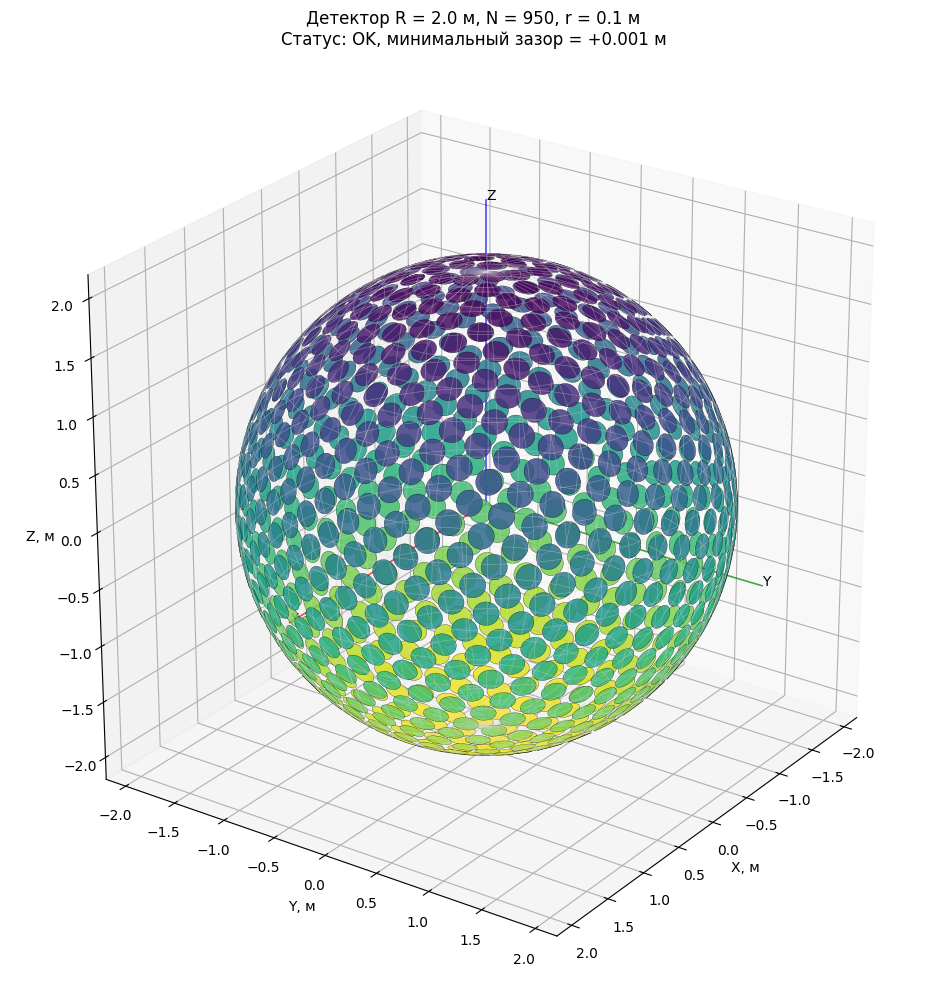

(<Figure size 1000x1000 with 1 Axes>,
 <Axes3D: title={'center': 'Детектор R = 2.0 м, N = 950, r = 0.1 м\nСтатус: OK, минимальный зазор = +0.001 м'}, xlabel='X, м', ylabel='Y, м', zlabel='Z, м'>)

In [48]:
det = Detector(pmt_number=950)
plot_detector(det)

In [53]:
det.pmt_centers[4]

array([-0.05341653, -0.26940146,  1.98105263])

In [68]:
import numpy as np
import k3d


def plot_detector_k3d_fast(det, show_normals=False, sphere_opacity=0.15,
                           n_circle=12, n_theta=16, n_phi=32):
    """
    Быстрая визуализация сферического детектора с ФЭУ в K3D.

    Вся геометрия ФЭУ собирается в ОДИН mesh с вершинным атрибутом цвета,
    что даёт один draw call вместо N.

    Параметры:
        det            : объект Detector (radius, pmt_number, pmt_radius, pmt_centers)
        show_normals   : рисовать нормали одним объектом k3d.line
        sphere_opacity : прозрачность каркасной сферы (0 — скрыть)
        n_circle       : число вершин на окружности диска (12–16 достаточно)
        n_theta, n_phi : разрешение сетки сферы

    Возвращает:
        plot : k3d.Plot
    """
    R = det.radius
    N = det.pmt_number
    r = det.pmt_radius
    centers = det.pmt_centers.astype(np.float32)
    u = (centers / np.linalg.norm(centers, axis=1, keepdims=True)).astype(np.float32)

    plot = k3d.plot()

    # ============================================================
    # 1. СФЕРА — один mesh
    # ============================================================
    if sphere_opacity > 0:
        theta = np.linspace(0, np.pi, n_theta, dtype=np.float32)
        phi = np.linspace(0, 2 * np.pi, n_phi, dtype=np.float32)
        TH, PH = np.meshgrid(theta, phi, indexing='ij')

        sv = np.stack([
            R * np.sin(TH) * np.cos(PH),
            R * np.sin(TH) * np.sin(PH),
            R * np.cos(TH),
        ], axis=-1).reshape(-1, 3).astype(np.float32)

        # индексы треугольников
        i_idx = np.arange(n_theta - 1)[:, None]
        j_idx = np.arange(n_phi - 1)[None, :]
        a = (i_idx * n_phi + j_idx).ravel()
        b = a + 1
        c = a + n_phi
        d = c + 1
        si = np.concatenate([
            np.stack([a, b, d], axis=1),
            np.stack([a, d, c], axis=1),
        ]).astype(np.uint32)

        plot += k3d.mesh(sv, si, color=0x888888, wireframe=True,
                         opacity=sphere_opacity, side='double')

    # ============================================================
    # 2. ВСЕ ФЭУ — ОДИН mesh с вершинным цветом
    # ============================================================
    # Локальный базис для каждого ФЭУ (векторизованно)
    ref = np.where(np.abs(u[:, 2:3]) < 0.9,
                   np.array([0.0, 0.0, 1.0], dtype=np.float32),
                   np.array([1.0, 0.0, 0.0], dtype=np.float32))
    e1 = np.cross(u, ref)
    e1 /= np.linalg.norm(e1, axis=1, keepdims=True)
    e2 = np.cross(u, e1)

    # Точки окружности: (N, n_circle, 3)
    t = np.linspace(0, 2 * np.pi, n_circle, endpoint=False, dtype=np.float32)
    cos_t = np.cos(t)[None, :, None]        # (1, n_circle, 1)
    sin_t = np.sin(t)[None, :, None]
    # circle[k, j] = C[k] + r*(cos_t[j]*e1[k] + sin_t[j]*e2[k])
    circle = (centers[:, None, :]
              + r * (cos_t * e1[:, None, :] + sin_t * e2[:, None, :]))  # (N, n_circle, 3)

    # Вершины: центр + n_circle точек → (N*(1+n_circle), 3)
    disk_verts = np.concatenate([
        centers[:, None, :],                 # (N, 1, 3) — центры
        circle,                              # (N, n_circle, 3)
    ], axis=1).reshape(-1, 3).astype(np.float32)

    # Индексы: для каждого диска — веер из n_circle треугольников
    # база для диска k: k*(n_circle+1); центр = база, точки = база+1..база+n_circle
    k = np.arange(N, dtype=np.uint32)[:, None]
    base = (k * (n_circle + 1)).astype(np.uint32)          # (N, 1)
    j = np.arange(n_circle, dtype=np.uint32)[None, :]      # (1, n_circle)
    v1 = base + 1 + j
    v2 = base + 1 + (j + 1) % n_circle
    tri = np.stack([np.broadcast_to(base, v1.shape), v1, v2], axis=-1)  # (N, n_circle, 3)
    disk_indices = tri.reshape(-1, 3).astype(np.uint32)

    # Цвета вершин: каждому диску — свой оттенок (палитра viridis через k3d-атрибут)
    # k3d ждёт цвета в формате uint32 0xRRGGBB
    hue = np.linspace(0.0, 1.0, N, dtype=np.float32)
    # простая HSV→RGB палитра без matplotlib для скорости
    h = hue * 6.0
    i_h = np.floor(h).astype(int) % 6
    f = h - np.floor(h)
    p, q, v = 1 - f, 1 - f, np.ones_like(f)       # упрощённо, для N больших достаточно
    # используем фиксированную приятную палитру: от синего к красному
    rr = np.clip(1.5 - np.abs(hue * 3.0 - 2.0), 0, 1)
    gg = np.clip(1.5 - np.abs(hue * 3.0 - 1.0), 0, 1)
    bb = np.clip(1.5 - np.abs(hue * 3.0 - 0.0), 0, 1)
    rgb = np.stack([rr, gg, bb], axis=1)                     # (N, 3) в [0,1]
    colors_per_pmt = (rgb * 255).astype(np.uint32)           # (N, 3)
    color_u32 = ((colors_per_pmt[:, 0] << 16)
                 | (colors_per_pmt[:, 1] << 8)
                 | colors_per_pmt[:, 2]).astype(np.uint32)   # (N,)

    # повторить цвет на (1 + n_circle) вершин каждого диска
    vert_colors = np.repeat(color_u32, n_circle + 1)         # (N*(n_circle+1),)

    plot += k3d.mesh(
        disk_verts, disk_indices,
        colors=vert_colors,       # вершинный атрибут цвета
        opacity=0.85,
        side='double',
        wireframe=False,
    )

    # ============================================================
    # 3. НОРМАЛИ — один объект k3d.line
    # ============================================================
    if show_normals:
        p_inner = centers - 0.3 * R * u                      # (N, 3)
        # пары вершин: [C_0, p_0, C_1, p_1, ...]
        line_verts = np.empty((2 * N, 3), dtype=np.float32)
        line_verts[0::2] = centers
        line_verts[1::2] = p_inner
        # индексы: для каждой пары — отрезок (2k, 2k+1)
        seg = np.arange(N, dtype=np.uint32)[:, None]
        line_indices = np.stack([2 * seg, 2 * seg + 1], axis=-1).reshape(-1, 2).astype(np.uint32)

        plot += k3d.line(line_verts, line_indices, color=0xFF0000, width=0.5)

    # ============================================================
    # 4. Камера
    # ============================================================
    plot.camera = [R * 2.5, R * 2.5, R * 2.5, 0, 0, 0, 0, 0, 1]
    plot.display()
    return plot

In [69]:
# Создаём детектор (ваш класс)
det = Detector(radius=2.0, pmt_number=1000, pmt_radius=0.1)

# Визуализация
plot_detector_k3d(det, show_normals=False)

Output()